# ANÁLISE P2 | _The Numbers Domestic Box Office Dataset_
___
Análises voltadas para responder à pergunta P2.
___

### 0 | Importações
___

In [ ]:
# Manipulação de dados:
import pandas as pd
import numpy as np        

# Visualização de dados:
import plotly.express as px 
import plotly.io as pio
from plotly.subplots import make_subplots

pio.renderers.default='png'

In [3]:
df = pd.read_csv('../data/processed/tabela_tratada.csv') # Importando o dataset

### P2 | Influência dos outros fins de semana na arrecadação da bilheteria
___

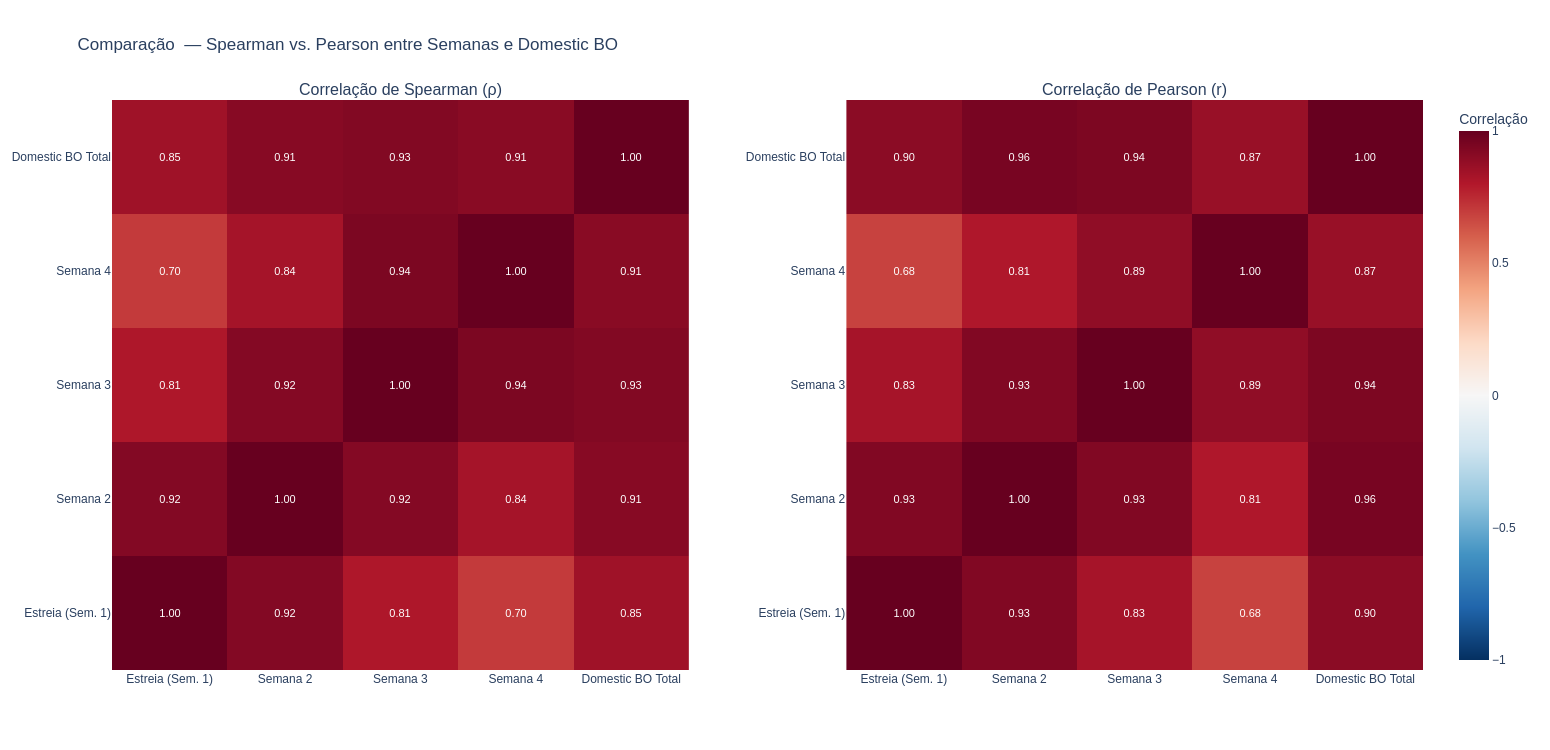

In [ ]:
col_estreia = 'estreia_bilheteria'
col_total = 'domestic_bo'

cols_semanas = sorted(
    [c for c in df.columns if c.startswith('semana_') and c.split('_')[1].isdigit()],
    key=lambda x: int(x.split('_')[1])
)

cols_analise = [col for col in ([col_estreia] + cols_semanas + [col_total]) if col in df.columns]

# 3. Prepara os dados e calcula as duas matrizes de correlação
base = df[cols_analise].replace([np.inf, -np.inf], np.nan)

corr_spearman = base.corr(method='spearman')
corr_pearson = base.corr(method='pearson')

rotulos = {
    'estreia_bilheteria': 'Estreia (Sem. 1)',
    'domestic_bo': 'Domestic BO Total'
}
for c in cols_semanas:
    rotulos[c] = f"Semana {c.split('_')[1]}"

mat_spearman = corr_spearman.rename(index=rotulos, columns=rotulos)
mat_pearson = corr_pearson.rename(index=rotulos, columns=rotulos)

# 4. Cria figura com dois heatmaps lado a lado e barra de cores compartilhada
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=('Correlação de Spearman (ρ)', 'Correlação de Pearson (r)'),
    horizontal_spacing=0.12
)

hm_spearman = px.imshow(
    mat_spearman,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1
).data[0]

hm_pearson = px.imshow(
    mat_pearson,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1
).data[0]

# Vincula ambos os heatmaps à mesma escala de cores ('coloraxis')
hm_spearman.update(coloraxis='coloraxis', showscale=False)
hm_pearson.update(coloraxis='coloraxis', showscale=True)

fig.add_trace(hm_spearman, row=1, col=1)
fig.add_trace(hm_pearson, row=1, col=2)

# 5. Ajustes visuais e formatação dos textos internos
fig.update_traces(texttemplate='%{z:.2f}', textfont_size=11)

fig.update_layout(
    title='Comparação  — Spearman vs. Pearson entre Semanas e Domestic BO',
    width=1550,
    height=750,
    template='plotly_white',
    coloraxis=dict(
        colorscale='RdBu_r',
        cmin=-1,
        cmax=1,
        colorbar=dict(title='Correlação')
    )
)

fig.show()

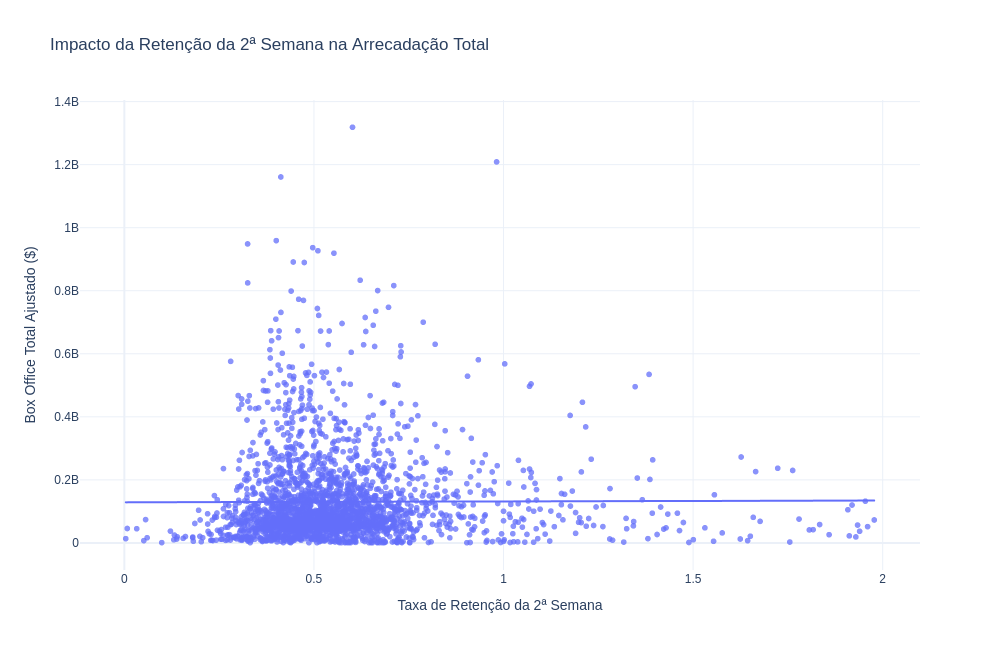

In [5]:
df_plot = df.dropna(subset=['estreia_bilheteria', 'semana_2', 'domestic_bo']).copy()

# 2. Calcula a Taxa de Retenção (Semana 2 / Estreia)
df_plot['retencao_semana_2'] = df_plot['semana_2'] / df_plot['estreia_bilheteria']

# Filtra eventuais distorções extremas de dados (ex: filmes com lançamento limitado que expandiram salas na semana 2)
df_plot = df_plot[(df_plot['retencao_semana_2'] > 0) & (df_plot['retencao_semana_2'] <= 2.0)]

# 3. Cria o Gráfico de Dispersão com Linha de Tendência
fig = px.scatter(
    df_plot,
    x='retencao_semana_2',
    y='domestic_bo',
    hover_name='nome',
    hover_data=['year', 'genre', 'estreia_bilheteria', 'semana_2'],
    trendline='ols',          # Linha de tendência estatística (requer statsmodels)
    title='Impacto da Retenção da 2ª Semana na Arrecadação Total',
    labels={
        'retencao_semana_2': 'Taxa de Retenção (Semana 2 / Estreia)',
        'domestic_bo': 'Box Office Doméstico Total ($)'
    },
    #color='genre',            # Colore os pontos por gênero para análise detalhada
    opacity=0.75
)

# 4. Ajustes visuais (Escala log no eixo Y para bilheterias)
fig.update_layout(
    xaxis_title='Taxa de Retenção da 2ª Semana ',
    yaxis_title='Box Office Total Ajustado ($)',
    #yaxis_type='log',
    width=1000,
    height=650,
    template='plotly_white'
)

# Exibe o gráfico interativo
fig.show()

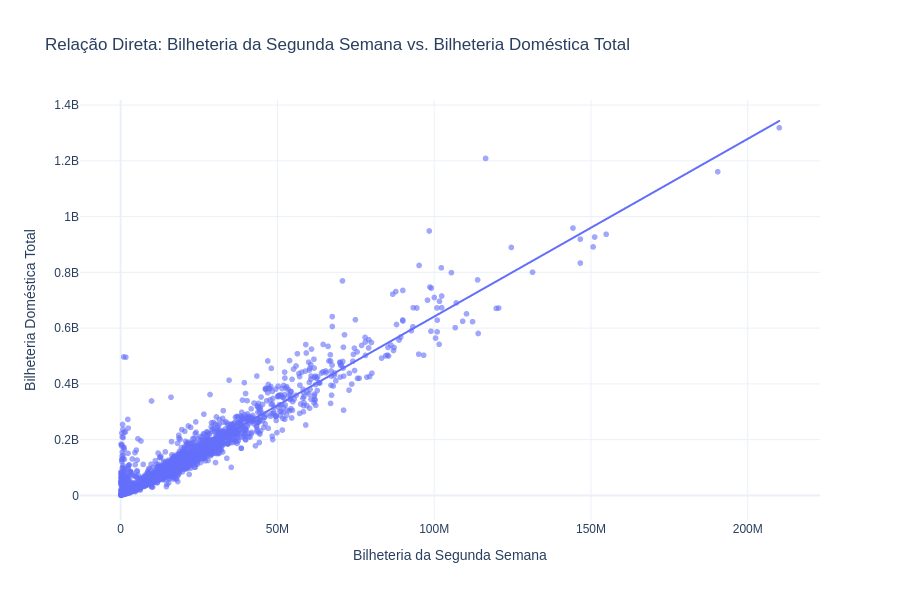

In [6]:
df_plot = df.dropna(subset=['semana_2', 'domestic_bo']).copy()

# Cria o gráfico de dispersão
fig = px.scatter(
    df_plot,
    x='semana_2',
    y='domestic_bo',
    hover_name='nome',
    #color='genre',
    hover_data=['year', 'genre', 'tn_legs'],
    trendline='ols',          # Linha de tendência estatística
    title='Relação Direta: Bilheteria da Segunda Semana vs. Bilheteria Doméstica Total',
    labels={
        'semana_2': 'Bilheteria da Segunda Semana ($)',
        'domestic_bo': 'Bilheteria Doméstica Total ($)'
    },
    opacity=0.6
)

fig.update_layout(
    #xaxis_type='log',
    #yaxis_type='log',
    xaxis_title='Bilheteria da Segunda Semana',
    yaxis_title='Bilheteria Doméstica Total',
    width=900,
    height=600,
    template='plotly_white'
)

fig.show()